# Constraint Diagram
- We need to rigorously update this: Examine the weights, everything is a fraction but the weights (MTOW) changes.
- Develop accurate equations for a propeller.

---

#### Future Work: Sensitivity Analysis on:
- $\frac{P}{W}$ depending on Velocities at different conditions, AR, $eta_p$ at different conditions, $C_{L,Max}$, $C_{D,0}$


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from ambiance import Atmosphere
import pint
ureg = pint.UnitRegistry()

Fundamental Constants:

---

In [37]:
MTOW=50696.72136*ureg.pound_force #[lbf] note: PLACEHOLDER
eta_pcruise=0.9
C_D0=0.02 # Taken from The annual aircraft design book (blue), page 6-7. 
AR=12 # competitively assessed
e=0.85 # competitively assessed (at cruise)
k=1/(np.pi*e*AR)
M_cruise=0.48 #cruise mach, competitively assessed 
cruise_alt=20000*ureg.feet #cruise altitude [input feet], competitively assessed
landing_distance=(3500*ureg.feet).magnitude # [ft] landing and takeoff distance at sea level, 
                                                # potentially multiply by 0.6 is a factor for hot days and high altitudes
#take_off_alt=(0*ureg.feet).magnitude #[ft] altitude of takeoff


$$ W_l= X * MTOW $$

This was derived with the following: 
$ W_L=W_{TO}\left[\frac{W_{pl}}{W_{TO}}+EWF+  (\approx{0})\right] $ From sizing excel sheet we have an estimate for $W_{TO}, EWF, \frac{W_{pl}}{W_{TO}}$

In [38]:
# Mission state fractions, all relative to MTOW
f_TO     = 0.970 # From sizing spreadsheet
f_climb  = 0.985
f_cruise = 0.932134858
f_land   = 0.995

beta_takeoff = 1.00
beta_V2      = 0.995          # conservative preliminary OEI value
beta_cruise  = f_TO * f_climb # start-of-cruise: highest cruise power required
beta_landing = f_TO * f_climb * f_cruise * f_land


fuel_fraction_mission = 1 - beta_landing
fuel_fraction_sized = 1.06 * fuel_fraction_mission

print(f"Start-of-cruise beta: {beta_cruise:.4f}")
print(f"Landing beta:         {beta_landing:.4f}")
print(f"Sized fuel fraction:  {fuel_fraction_sized:.4f}")

Start-of-cruise beta: 0.9554
Landing beta:         0.8862
Sized fuel fraction:  0.1207


Cruise Velocity Constraint: We need to be able to maintain a cruise speed


In [39]:
# cruise velocity constraint

sealevel = Atmosphere(0) # gives SI 
# NOTE: THIS CHANGES WITH ALTITUDE, current: 20000 ft
a_cruisealt = (Atmosphere(cruise_alt.to("meters").magnitude).speed_of_sound)*ureg("m/s").to("ft/s").magnitude # ISA to find speed of sound, convert to (ft/s)
rho_cruisealt=Atmosphere(cruise_alt.to("meters").magnitude).density*ureg("kg/m^3").to("slug/ft^3").magnitude # ISA to find density at cruise altitude (slug/ft^3)
rho_sl=sealevel.density*ureg("kg/m^3").to("slug/ft^3").magnitude # sea-level slug/ft^3
V_cruise=M_cruise*a_cruisealt #ft/sec
W_S=np.linspace(1, 200, 1000) # linspace for wingload
q_cruise=0.5*rho_cruisealt*V_cruise**2 # dynamic pressure at cruise

alpha_T_cruise=1 # NOTE: Input engine model later
alpha_P_cruise=1 # cruise power available/sea-level power estimate
T_W_cruise=(q_cruise*C_D0*(1/W_S)+(k/q_cruise)*W_S)/alpha_T_cruise # above line = valid
"""
P_W_cruise =( 
    (V_cruise / 
    (550 * eta_pcruise * alpha_P_cruise))*
    (q_cruise*C_D0/W_S +(k*(W_S/q_cruise)*beta_cruise**2)) # the 550 is to get horsepower
)
"""
P_W_cruise=2.1**3 * np.sqrt(rho_cruisealt/rho_sl) / W_S



Attempting a Propeller Takeoff Constraint
(sensitive)


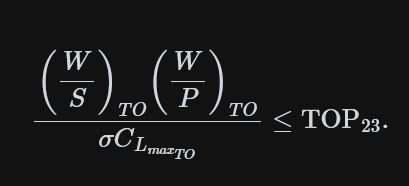

In [40]:
# part 23 takeoff field length constraint
from scipy.optimize import fsolve

s_TOFL_required = 4500       # ft
sigma_TO = 1.0
C_L_max_TO = 1.7

s_tog_required = s_TOFL_required * 1.66

def takeoff_field_length(TOP_23):
    return 4.9 * TOP_23 + 0.009 * TOP_23**2

TOP_23 = fsolve(
    lambda TOP_23: takeoff_field_length(TOP_23) - s_tog_required,
    x0=0.5
)[0]

P_W_takeoff = 1.0 / ((TOP_23 * sigma_TO * C_L_max_TO) / W_S)

Landing Constraint: Must be able to land a certain distance at stall speed.

In [41]:
# landing constraint
V_approach=np.sqrt(landing_distance/0.3) #roskam page 111 (NOTE: verify this works for part 25)

V_stall = V_approach/1.3 # page 111 roskam , in knots, need to convert to ft/sec
V_stall = V_stall*1.68781 # convert knots to ft/sec
C_L_max_L = 2.5 # page 91 roskam (estimated, competitive)
W_S_landing = 0.5 * rho_sl * V_stall**2 * C_L_max_L / beta_landing # roskam equation 3.1 , then 
W_S_landing = float(np.squeeze(W_S_landing))                       #  weight fraction to get in terms of takeoff w/s
print(f"W_S_landing: {W_S_landing}")


W_S_landing: 65.93514178715695


Selected design point: W/S = 81.7 lbf/ft², P/W = 0.14 hp/lbf
Required installed shaft power: 7344 shp
Wing area: 620.2 ft²
Span: 86.3 ft, mean chord: 7.2 ft


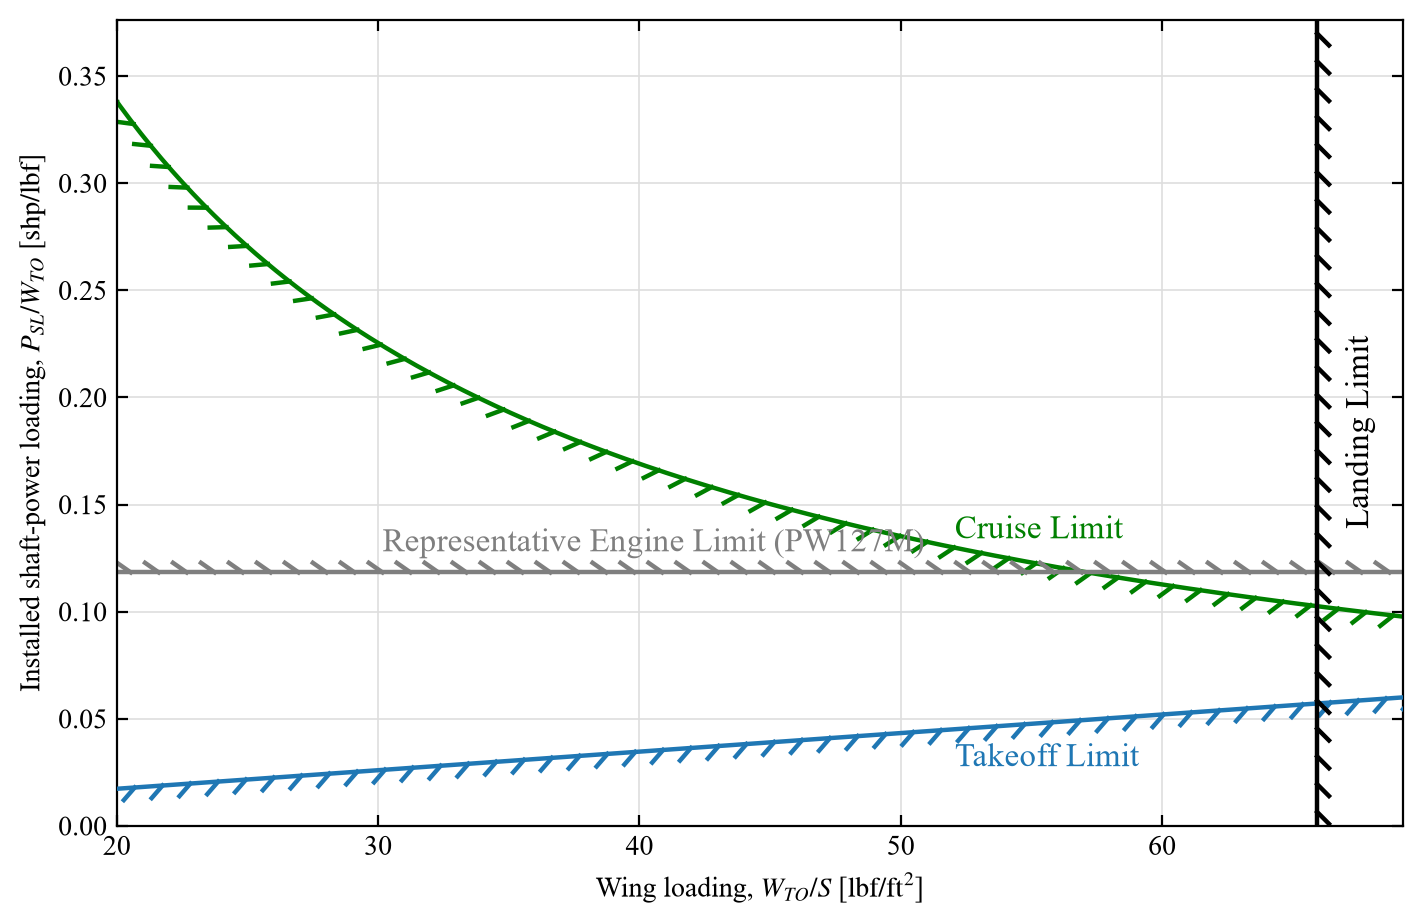

In [42]:
# AIAA-style constraint diagram
# The 7.0-in width is suitable for a two-column AIAA figure.
from IPython.display import Math, display
plt.rcParams.update({
    'font.family': 'times new roman',
    'font.serif': ['STIX Two Text', 'Times New Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 10,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
})
P_W_required = np.maximum.reduce([
    P_W_cruise,
    P_W_takeoff,
])
# The landing constraint is an upper limit on takeoff wing loading.
feasible = W_S <= W_S_landing
if not np.any(feasible):
    raise ValueError("Landing constraint lies outside the W/S grid.")

# Lowest installed-power design that satisfies every plotted constraint.
P_W_feasible = np.where(feasible, P_W_required, np.inf)
i_design = np.argmin(P_W_feasible)

W_S_design = W_S[i_design]+16  # getting us in a better position relative to other planes
P_W_design = P_W_required[i_design]+0.042# just getting us somewhere close

fig, ax = plt.subplots(
    figsize=(7.0, 4.5),
    dpi=200,
    constrained_layout=True,
)

cruise_line, = ax.plot(
    W_S, P_W_cruise, color="green", lw=1.6
)

takeoff_line, = ax.plot(
    W_S, P_W_takeoff, color="tab:blue", lw=1.6,

    zorder=3
)
landing_line = ax.axvline(
    W_S_landing, color="black", lw=1.6,
    zorder=3
)
engine_limit = (
    6000 * ureg.horsepower / MTOW
).to("horsepower / pound_force").magnitude
engine_line = ax.axhline( # PW127M limit (estimated)
engine_limit, color="tab:gray", lw=1.6, label = rf"PW127M Limit, $P/W={engine_limit:.1f}\,\mathrm{{hp/lbf}}$"
)
for line, color in [
    (cruise_line, "green"),
    (takeoff_line, "tab:blue"),
    (landing_line, "black"),
    #(engine_line, "tab:gray")
]:
    line.set_path_effects([
        pe.withTickedStroke(
            spacing=10, angle=585, length=0.6, foreground=color
        )
    ])
engine_line.set_path_effects([
    pe.withTickedStroke(
        spacing=10, angle=585-80, length=0.6, foreground="tab:gray"
    )
])

design_point=ax.scatter(
    W_S_design, P_W_design, s=80, marker="o",
    facecolor="red", edgecolor="black", linewidth=1.1, zorder=6,
    label = rf"Design point: $W/S = {W_S_design:.1f}\ \mathrm{{lbf/ft^2}}, \ P/W = {P_W_design:.2f}\ \mathrm{{hp/lbf}})$"
)

x_visible = (W_S >= 20) & (W_S <= 1.05 * W_S_landing)
y_top = 1.12 * np.max(P_W_required[x_visible])
'''
ax.legend(
    handles=[design_point],
    frameon=True,
    fancybox=False,
    edgecolor="black",
)
'''
ax.set_xlim(20, 1.05 * W_S_landing)
ax.set_ylim(0, y_top)
ax.set_xlabel(r"Wing loading, $W_{TO}/S$ [$\mathrm{lbf/ft^2}$]")
ax.set_ylabel(r"Installed shaft-power loading, $P_{SL}/W_{TO}$ [$\mathrm{shp/lbf}$]")
ax.tick_params(which="both", direction="in", top=True, right=True,
               width=0.8, length=4)
ax.grid(True, which="major", color="0.87", linewidth=0.6, zorder=0)

x_label = 0.78 * W_S_landing

ax.annotate(
    "Cruise Limit",
    xy=(x_label, np.interp(x_label, W_S, P_W_cruise)),
    xytext=(6, 5), textcoords="offset points",
    color="green", va="center",
)
ax.annotate(
    "Takeoff Limit",
    xy=(x_label, np.interp(x_label, W_S, P_W_takeoff)),
    xytext=(6, -10), textcoords="offset points",
    color="tab:blue", va="center",
)
ax.annotate(
    "Landing Limit",
    xy=(W_S_landing, 0.75 * y_top),
    xytext=(10, -76), textcoords="offset points",
    rotation=90, color="black", va="center",
)
ax.annotate(
    "Representative Engine Limit (PW127M)",
    xy=(x_label, engine_limit),
    xytext=(-200, 5), textcoords="offset points",
    color="tab:gray", va="bottom",
)

fig.savefig(
    "sizing_constraint_diagram_AIAA.png",
    dpi=300, facecolor="white", bbox_inches="tight",
)

W_S_design_qty = W_S_design * ureg.pound_force / ureg.feet**2
S = (MTOW / W_S_design_qty).to("ft^2")
P_shaft = (P_W_design * ureg.horsepower / ureg.pound_force * MTOW).to("horsepower")
b = np.sqrt(S.magnitude * AR)
c_bar = b / AR

print(f"Selected design point: W/S = {W_S_design:.1f} lbf/ft², P/W = {P_W_design:.2f} hp/lbf")

print(f"Required installed shaft power: {P_shaft.magnitude:.0f} shp")
print(f"Wing area: {S.magnitude:.1f} ft²")
print(f"Span: {b:.1f} ft, mean chord: {c_bar:.1f} ft")

In [43]:
M_48=MTOW/65 
M_55=MTOW/63
diff=100*abs(M_48-M_55)/M_48
print(diff)

3.174603174603168 dimensionless
